# 04 - Weather & Environmental Conditions

**Objective:** examine how temperature, humidity, wind and weather category relate to rental demand, and whether this differs by user type.
**Grain:** `day.csv` (one row per day). Weather variables are de-normalized to °C, %, and km/h.

*Caution:* weather is strongly confounded with season (and both with daylight and tourism). The univariate associations here are re-examined jointly in notebook 06.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", message="findfont")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.visualization.style import apply_matplotlib_style
apply_matplotlib_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)
from src.data.clean import load_processed
from src.analysis import kpis as K, stats as S
from src.visualization import figures as F
day = load_processed("day")

## Temperature

,temp_band,days,mean_cnt,mean_casual,mean_registered
0,"[0, 5)",4,"1,437.75",106.00,"1,331.75"
1,"[5, 10)",56,"1,694.91",124.29,"1,570.62"
2,"[10, 15)",161,"3,263.96",404.47,"2,859.48"
3,"[15, 20)",138,"4,191.98",748.79,"3,443.19"
4,"[20, 25)",130,"5,577.28","1,164.16","4,413.12"
5,"[25, 30)",170,"5,726.24","1,243.16","4,483.07"
6,"[30, 35)",71,"5,417.99","1,127.51","4,290.48"


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


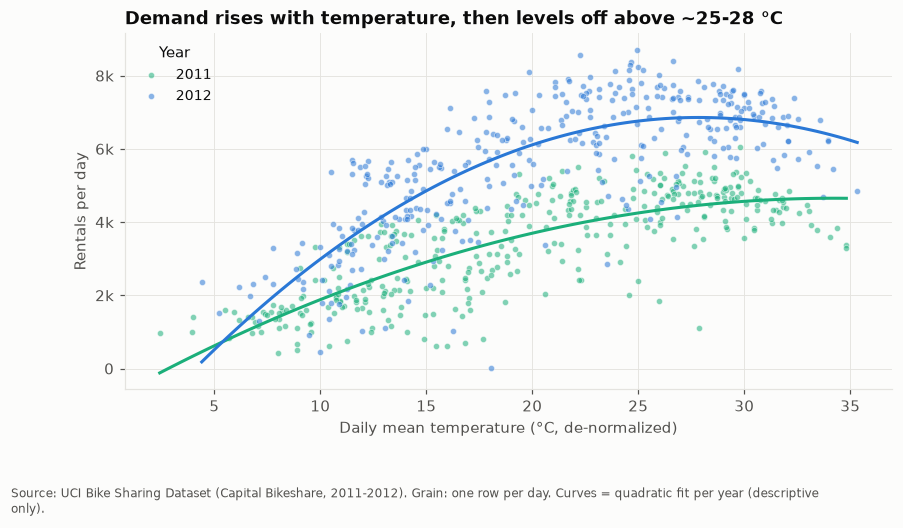

In [2]:
display(K.temperature_bands(day))
F.fig_temperature(day); plt.show()

Demand rises steeply from 5 to 25 °C and is flat to slightly lower above about 28 °C. The relationship is clearly non-linear, which is why the regression uses a quadratic term. Feels-like temperature correlates almost perfectly with actual temperature:

In [3]:
day[['temp_c', 'atemp_c']].corr()

,temp_c,atemp_c
temp_c,1.00,0.99
atemp_c,0.99,1.00


## Humidity and wind

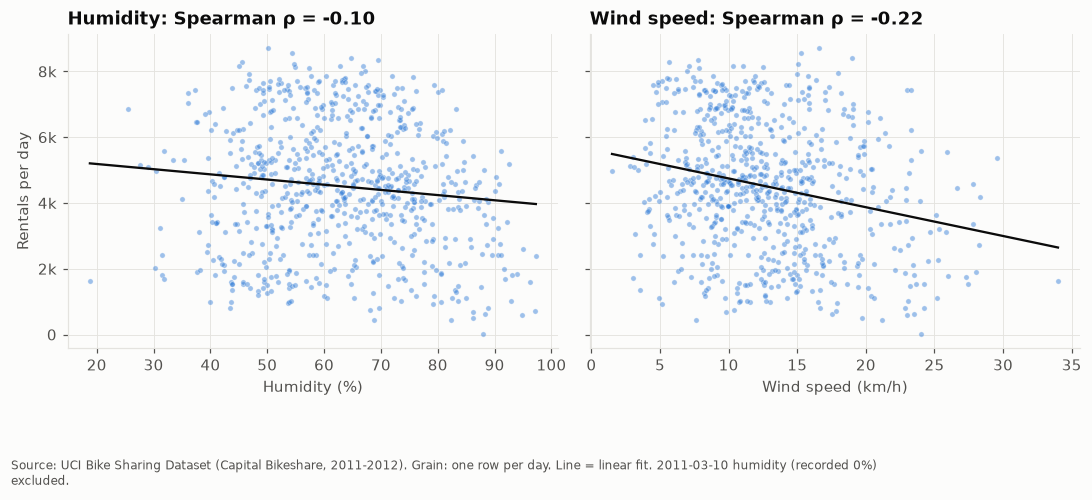

In [4]:
F.fig_humidity_wind(day); plt.show()

## Correlations with uncertainty
Spearman's rho is used (robust to the non-linear temperature shape). CIs come from a 14-day moving-block bootstrap, because consecutive days are not independent.

,target,variable,n,pearson_r,spearman_rho,spearman_ci_low,spearman_ci_high
0,cnt,temp_c,731,0.63,0.62,0.43,0.73
1,cnt,atemp_c,731,0.63,0.62,0.42,0.73
2,cnt,hum_pct,730,-0.11,-0.10,-0.24,0.02
3,cnt,windspeed_kmh,731,-0.23,-0.22,-0.30,-0.13
4,casual,temp_c,731,0.54,0.67,0.53,0.74
5,casual,atemp_c,731,0.54,0.67,0.53,0.74
6,casual,hum_pct,730,-0.09,-0.08,-0.20,0.03
7,casual,windspeed_kmh,731,-0.17,-0.18,-0.26,-0.10
8,registered,temp_c,731,0.54,0.53,0.32,0.66
9,registered,atemp_c,731,0.54,0.53,0.32,0.66


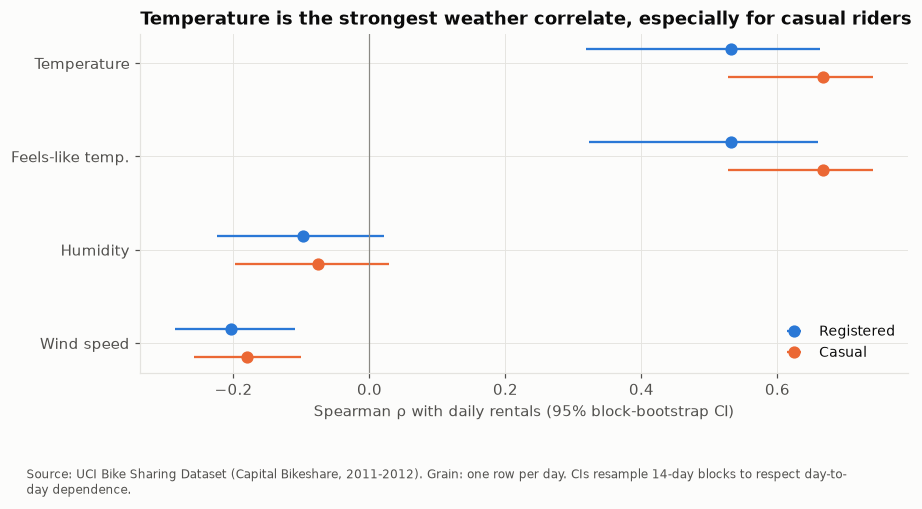

In [5]:
corr = S.weather_correlations(day)
display(corr)
F.fig_correlations(corr); plt.show()

- Temperature: rho is about 0.62 for total rentals. The casual point estimate (0.67) is higher than the registered one (0.53), but **the confidence intervals overlap**, so this is suggestive rather than conclusive.
- Humidity: weak, and the CI includes zero. Wind speed: weak negative association.

## Weather category

,cnt,casual,registered,cnt_index,casual_index,registered_index,days
weather_group,,,,,,,
Clear / partly cloudy,"4,876.79",964.03,"3,912.76",100.00,100.00,100.00,463
Mist / cloudy,"4,035.86",687.35,"3,348.51",82.76,71.30,85.58,247
Rain / snow,"1,803.29",185.48,"1,617.81",36.98,19.24,41.35,21


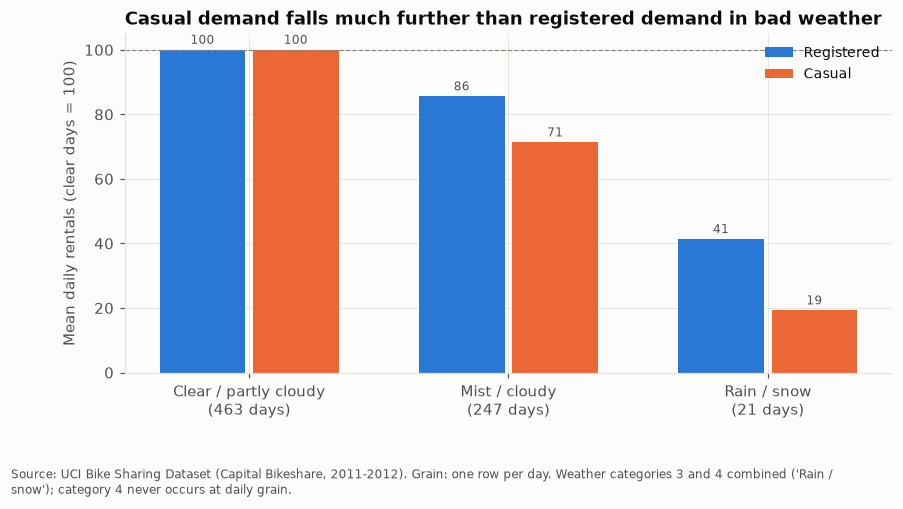

In [6]:
display(K.weather_sensitivity(day))
F.fig_weather_sensitivity(day); plt.show()

## Conclusions
1. Temperature is the strongest continuous weather correlate. Demand plateaus above about 25-28 °C.
2. Rain/snow days average about 37% of clear-day demand. Casual demand drops to about 19% of its clear-day level, registered demand to about 41%. Casual users are much more weather-sensitive.
3. Humidity and wind have weak marginal associations.

**Limitations:** only 21 rain/snow days at daily grain; daily weather is a single summary per day (rain in one hour may not affect the whole day); associations only.